In [25]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm

In [26]:
def initialisation(n_0,n_1,n_2):
  W1 = np.random.randn(n_1, n_0)
  b1=np.zeros((n_1,1))
  W2 = np.random.randn(n_2, n_1)
  b2=np.zeros((n_2,1))

  parametres={
      'W1':W1,
      'b1':b1,
      'W2':W2,
      'b2':b2
  }
  return parametres

In [27]:
def model(X,parametres):
  eps = 1e-15
  W1=parametres['W1']
  b1=parametres['b1']
  W2=parametres['W2']
  b2=parametres['b2']

  Z1=W1.dot(X)+b1

  Z1 = np.clip(Z1, -500, 500)
  A1=1/(1+np.exp(-Z1))
  #A1 = np.clip(A1, eps, 1 - eps)
  Z2=W2.dot(A1)+b2

  A2=1/(1+np.exp(-Z2))
  #A2 = np.clip(A2, eps, 1 - eps)
  caches={
      'A1':A1,
      'A2':A2
  }
  return caches

In [28]:
def back_propagation(X,y,parametres,caches):
  W1=parametres['W1']
  b1=parametres['b1']
  W2=parametres['W2']
  b2=parametres['b2']
  A1=caches['A1']
  A2=caches['A2']
  m=y.shape[1]
  dZ2=A2-y
  dW2=(1/m)*dZ2.dot(A1.T)

  db2 = (1/m) * np.sum(dZ2, axis=1, keepdims=True)


  dZ1=W2.T.dot(dZ2)* (A1 * (1 - A1))
  dW1=(1/m)*dZ1.dot(X.T)
  db1 = (1/m) * np.sum(dZ1, axis=1, keepdims=True)

  gradients={
      'dW1':dW1,
      'db1':db1,
      'dW2':dW2,
      'db2':db2
  }
  return gradients

In [29]:
def cout(y,caches):
  A2=caches['A2']
  m=y.shape[1]
  cout=(-1/m)*np.sum(y*np.log(A2)+(1-y)*np.log(1-A2))
  return cout

In [30]:
def prediction(X,parametres):
  m=X.shape[1]
  p=np.zeros((1,m))
  caches=model(X,parametres)
  A2=caches['A2']
  p  = (A2 > 0.5).astype(int)
  return (p,A2)

In [31]:
def activation(parametres,activations,n=0.01,nb_iters=1000):
  W1=parametres['W1']
  b1=parametres['b1']
  W2=parametres['W2']
  b2=parametres['b2']
  dW1=activations['dW1']
  db1=activations['db1']
  dW2=activations['dW2']
  db2=activations['db2']
  W1=W1-n*dW1
  b1=b1-n*db1
  W2=W2-n*dW2
  b2=b2-n*db2
  parametres={
      'W1':W1,
      'b1':b1,
      'W2':W2,
      'b2':b2
  }
  return parametres

In [32]:
from sklearn.metrics import accuracy_score

In [33]:
def reseau_neurones(X_train,y_train,n_1,pas,nb_iters):
  n_0=X_train.shape[0]

  n_2=y_train.shape[0]
  train_loss=[]
  train_acc=[]

  parametres=initialisation(n_0,n_1,n_2)
  for i in tqdm(range(nb_iters)):

    caches = model(X_train, parametres)
    gradients = back_propagation(X_train, y_train, parametres, caches)



    parametres=activation(parametres,gradients,pas)

    if i%10==0:
      train_loss.append(cout(y_train,caches))
      y_pred = prediction(X_train, parametres)
      train_acc.append(accuracy_score(y_train.flatten(),y_pred[0].flatten()))
  plt.figure(figsize=(12,5))

  plt.subplot(1,2,1)
  plt.plot(train_loss,label='train loss')
  plt.legend()
  plt.title('Loss')

  plt.subplot(1,2,2)
  plt.plot(train_acc,label='train acc')
  plt.legend()
  plt.title('Accuracy')

  return parametres

In [34]:
def afficher_decision(X, y, parametres):
    x_min, x_max = X[0, :].min() - 0.1, X[0, :].max() + 0.1
    y_min, y_max = X[1, :].min() - 0.1, X[1, :].max() + 0.1

    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500),
                     np.linspace(y_min, y_max, 500))

    # Forme correcte pour l’entrée du modèle : (n_features, m)
    grille = np.c_[xx.ravel(), yy.ravel()].T
    Z = prediction(grille, parametres)
    Z = Z[0].reshape(xx.shape)



    y_pred=prediction(X_test,parametres)
    print(f"Le score de prédiction est de {accuracy_score(y_test.flatten(),y_pred[0].flatten())*100} %")

    # Tracé
    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, cmap="summer", alpha=0.5)
    plt.scatter(X[0, :], X[1, :], c=y.flatten(), cmap="summer", edgecolors='k')
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.show()

Dimensions de X est: (2, 2000)
Dimensions de y est: (1, 2000)


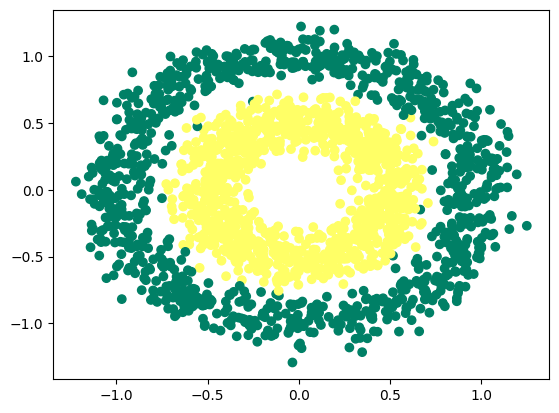

In [35]:
from sklearn.datasets import make_circles
X,y=make_circles(n_samples=2000,factor=0.52,noise=0.1,random_state=0)
y=y.reshape(1,y.shape[0])
X=X.T
print(f"Dimensions de X est: {X.shape}")
print(f"Dimensions de y est: {y.shape}")


plt.scatter(X[0,:],X[1,:],c=y,cmap="summer")
plt.show()

100%|██████████| 5000/5000 [00:24<00:00, 204.96it/s]


Le score de prédiction est de 96.0 %


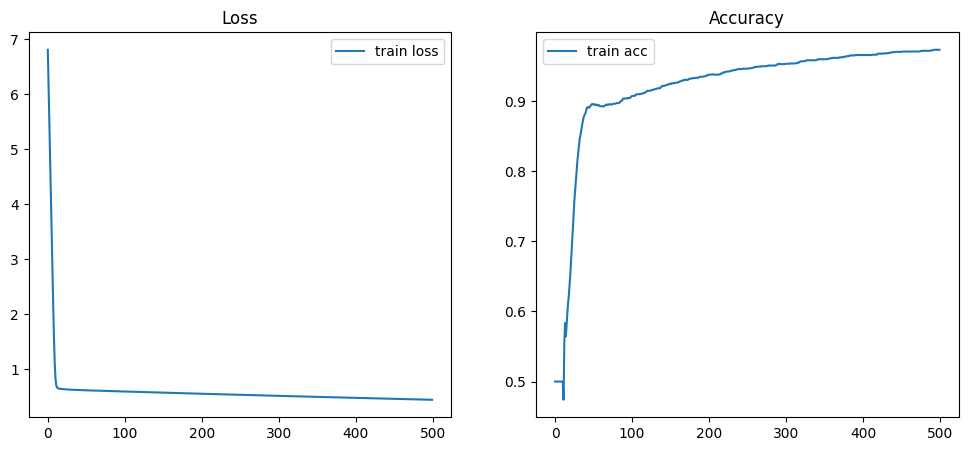

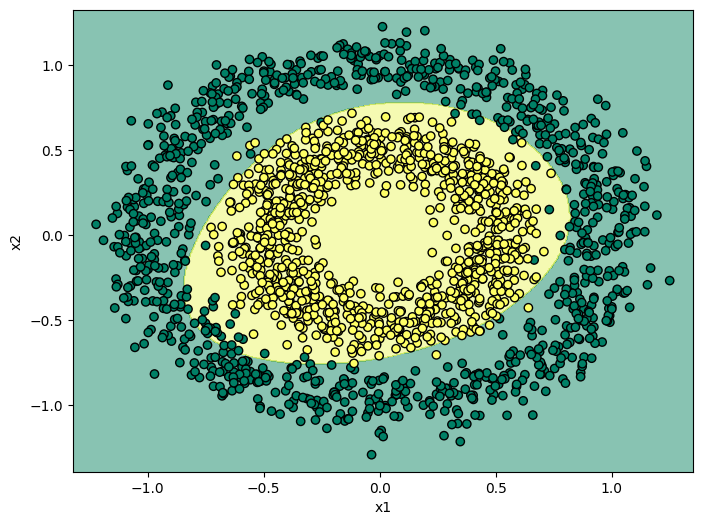

In [36]:
parametres=reseau_neurones(X,y,n_1=84,pas=0.01,nb_iters=5000)
afficher_decision(X, y, parametres)

In [37]:
from sklearn.model_selection import train_test_split

X_t,y_t=make_circles(n_samples=1000,factor=0.52,noise=0.1,random_state=0)

X_train,X_test,y_train,y_test=train_test_split(X_t,y_t,test_size=0.8,random_state=0)
y_train=y_train.reshape(1,y_train.shape[0])
y_test=y_test.reshape(1,y_test.shape[0])
X_train=X_train.T
X_test=X_test.T

print(f'Dimension de X_test: {X_test.shape} ')
print(f'Dimension de y_test: {y_test.shape} ')

y_predi=prediction(X_test,parametres)
print(f"Le score de prédiction est de {accuracy_score(y_test.flatten(),y_predi[0].flatten())*100} %")

Dimension de X_test: (2, 800) 
Dimension de y_test: (1, 800) 
Le score de prédiction est de 96.0 %


Le score de prédiction est de 96.0 %


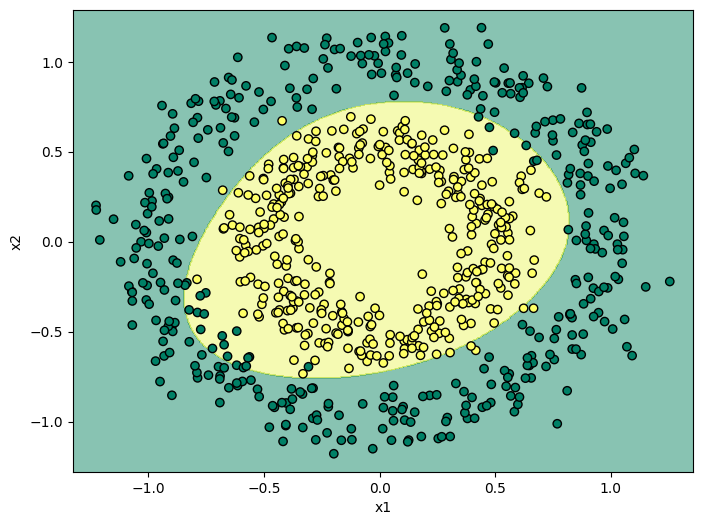

In [38]:

afficher_decision(X_test, y_test, parametres)

#Deploiement pour predire un point


In [39]:
def affichage_prediction(X, y, parametres,X_ap):
    x_min, x_max = X[0, :].min() - 0.1, X[0, :].max() + 0.1
    y_min, y_max = X[1, :].min() - 0.1, X[1, :].max() + 0.1

    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500),
                     np.linspace(y_min, y_max, 500))


    grille = np.c_[xx.ravel(), yy.ravel()].T
    Z = prediction(grille, parametres)
    Z = Z[0].reshape(xx.shape)



    y_pred=prediction(X_test,parametres)
    # Tracé
    plt.figure(figsize=(10, 8))
    plt.contourf(xx, yy, Z, cmap="summer", alpha=0.5)
    plt.scatter(X[0, :], X[1, :], c=y.flatten(), cmap="summer", edgecolors='k')
    plt.title("Frontière de décision du réseau de neurones")
    plt.scatter(X_ap[0], X_ap[1], color='red', s=25,label='Point entré',edgecolors='k')
    classe_predite = prediction(X_ap.reshape(2, 1), parametres)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.show()

Entrer la valeur de x1: 1
Entrer la valeur de x2: 0
La probabilité que votre point soit de la classe 0 est 59.79 %


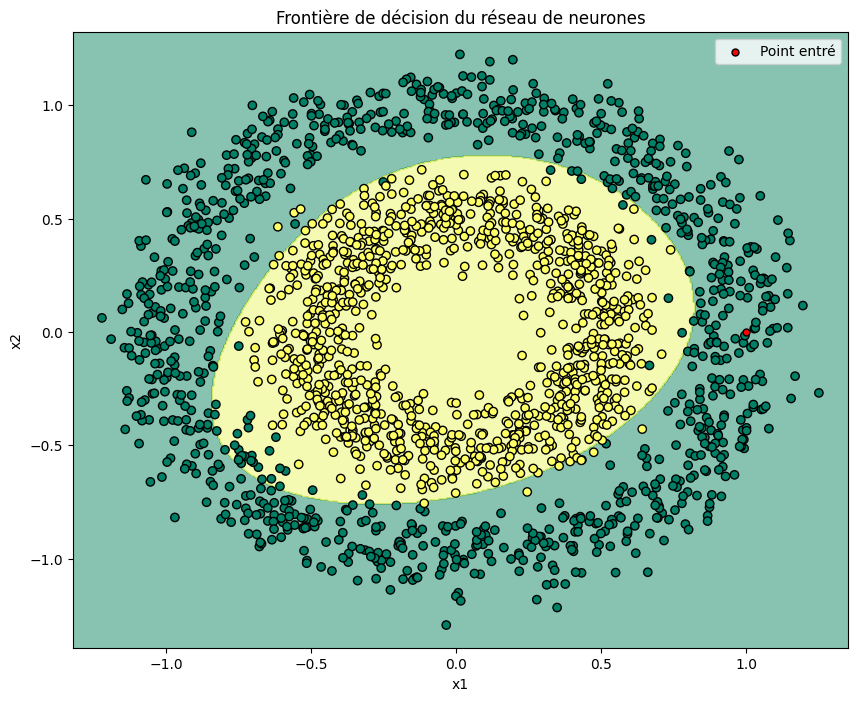

In [40]:
x1=input("Entrer la valeur de x1: ")
x2=input("Entrer la valeur de x2: ")
x1=float(x1)
x2=float(x2)
X_ap=np.array([[x1,x2]])
X_ap=X_ap.T
y_predi,A2=prediction(X_ap,parametres)
y_predi=y_predi.flatten()
if y_predi[0]==0:
  print(f"La probabilité que votre point soit de la classe {y_predi[0]} est {round((1-A2[0][0])*100,2)} %")
else:
  print(f"La probabilité que votre point soit de la classe {y_predi[0]} est {round(A2[0][0]*100,2)} %")

affichage_prediction(X, y, parametres,X_ap)


In [41]:
y_pred_test, _ = prediction(X_test, parametres)
accuracy = accuracy_score(y_test.flatten(), y_pred_test.flatten()) * 100
print(f"La précision globale du modèle sur l'ensemble de test est de: {accuracy:.2f} %")

La précision globale du modèle sur l'ensemble de test est de: 96.00 %


<Figure size 800x600 with 0 Axes>

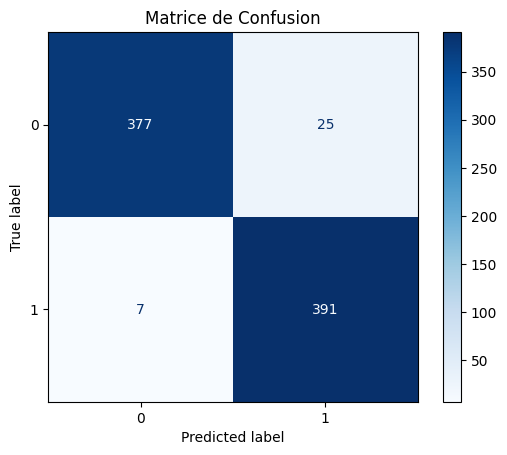

In [42]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate predictions for the test set
y_pred_test, _ = prediction(X_test, parametres)

# Compute the confusion matrix
cm = confusion_matrix(y_test.flatten(), y_pred_test.flatten())

# Display the confusion matrix
plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap=plt.cm.Blues)
plt.title('Matrice de Confusion')
plt.show()

### Exemple de chargement et d'aplatissement d'images avec PIL

Cet exemple va :
1.  Créer des répertoires factices et quelques images d'exemple (pour que le code soit exécutable).
2.  Charger ces images.
3.  Les redimensionner à une taille uniforme (ex: 64x64 pixels).
4.  Les convertir en niveaux de gris (pour simplifier l'aplatissement en un seul canal).
5.  Les aplatir en un vecteur 1D.
6.  Normaliser les valeurs des pixels entre 0 et 1.

In [43]:
from PIL import Image
import numpy as np
import os

# --- 1. Créer des répertoires et des images factices pour l'exemple ---

# Définir un répertoire pour les données d'images
data_dir = 'images_data'
os.makedirs(os.path.join(data_dir, 'chats'), exist_ok=True)
os.makedirs(os.path.join(data_dir, 'chiens'), exist_ok=True)

# Fonction pour créer une image factice
def create_dummy_image(path, color, size=(100, 100)):
    img = Image.new('RGB', size, color=color)
    img.save(path)

# Créer quelques images de chats (bleues)
create_dummy_image(os.path.join(data_dir, 'chats', 'chat1.png'), 'blue')
create_dummy_image(os.path.join(data_dir, 'chats', 'chat2.png'), 'darkblue')

# Créer quelques images de chiens (vertes)
create_dummy_image(os.path.join(data_dir, 'chiens', 'chien1.png'), 'green')
create_dummy_image(os.path.join(data_dir, 'chiens', 'chien2.png'), 'darkgreen')

print(f"Images factices créées dans '{data_dir}'")

Images factices créées dans 'images_data'


In [44]:
# --- 2. Charger, prétraiter et aplatir les images ---

image_size = (64, 64) # Taille cible pour le redimensionnement

all_flattened_images = []
all_labels = []

# Parcourir les catégories (chiens/chats)
for label_idx, category in enumerate(['chats', 'chiens']):
    category_path = os.path.join(data_dir, category)
    for filename in os.listdir(category_path):
        if filename.endswith(('.png', '.jpg', '.jpeg')):
            file_path = os.path.join(category_path, filename)

            # Charger l'image
            img = Image.open(file_path)

            # Redimensionner l'image
            img = img.resize(image_size)

            # Convertir en niveaux de gris (simplifie l'aplatissement)
            img = img.convert('L') # 'L' pour Luminance (niveaux de gris)

            # Convertir en tableau NumPy
            img_array = np.array(img)

            # Aplatir l'image en un vecteur 1D
            flattened_img = img_array.flatten()

            # Normaliser les pixels entre 0 et 1
            normalized_img = flattened_img / 255.0

            all_flattened_images.append(normalized_img)
            all_labels.append(label_idx) # 0 pour chats, 1 pour chiens

# Convertir la liste d'images aplaties en un tableau NumPy
X_images = np.array(all_flattened_images).T # Transposer pour avoir (n_features, m)
y_images = np.array(all_labels).reshape(1, -1)

print(f"Dimensions de X_images (caractéristiques, échantillons): {X_images.shape}")
print(f"Dimensions de y_images (étiquettes, échantillons): {y_images.shape}")

print("\nPremière image aplatie et normalisée (quelques premiers pixels):\n", X_images[:, 0][:10])
print("\nÉtiquettes des images: ", y_images)

# Nettoyage (optionnel): supprimer le dossier d'images factices
# import shutil
# shutil.rmtree(data_dir)

Dimensions de X_images (caractéristiques, échantillons): (4096, 4)
Dimensions de y_images (étiquettes, échantillons): (1, 4)

Première image aplatie et normalisée (quelques premiers pixels):
 [0.11372549 0.11372549 0.11372549 0.11372549 0.11372549 0.11372549
 0.11372549 0.11372549 0.11372549 0.11372549]

Étiquettes des images:  [[0 0 1 1]]


100%|██████████| 5000/5000 [00:17<00:00, 283.08it/s]


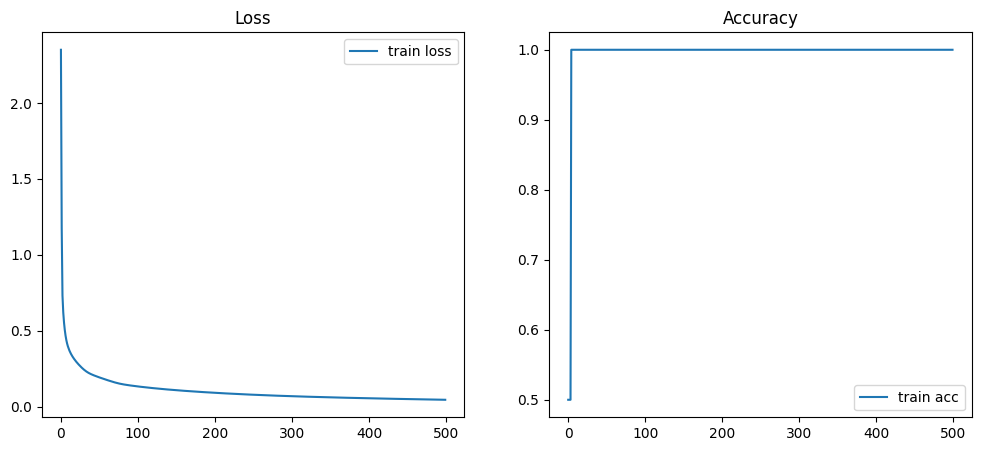

In [45]:
parametres_images = reseau_neurones(X_images, y_images, n_1=84, pas=0.01, nb_iters=5000)

Le modèle a été entraîné sur les images aplaties. Vous pouvez maintenant essayer d'afficher la frontière de décision ou de faire des prédictions sur de nouvelles images de test si vous en avez.

Avec `X_images` et `y_images` préparés de cette manière, vous auriez le bon format pour l'entrée de votre fonction `reseau_neurones`. Le `n_0` de votre modèle devrait être `X_images.shape[0]` (ici, `64 * 64 = 4096`).

**Rappel important :** Comme discuté, cette approche **ne préserve pas les informations spatiales** de l'image, ce qui est essentiel pour une bonne classification d'images. Attendez-vous à des performances très limitées avec ce type de modèle pour cette tâche.